# Document Image Quality Auditor

This notebook checks a document image for a few common capture problems: blur, skew, uneven lighting, glare, and very low text/ink coverage.

The example image is created below, so the notebook can run without downloading a dataset. Replace it with a document image of your own if you want to test a real scan or photo.

In [1]:
from pathlib import Path
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

OpenCV version: 4.13.0


## 1. Create an example document

This is a simple synthetic page with a heading, lines of text, and a small table. It is only for demonstrating the pipeline; it is not a benchmark image.

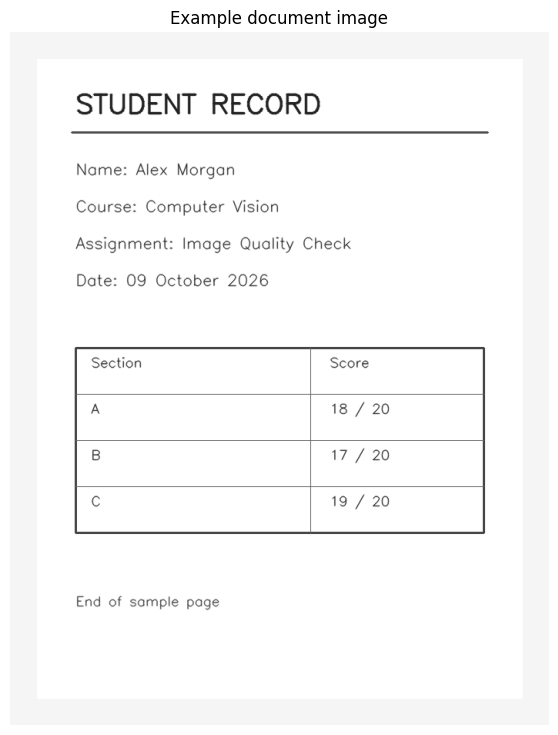

In [2]:
def make_sample_document():
    page = np.full((900, 700, 3), 245, dtype=np.uint8)
    cv2.rectangle(page, (35, 35), (665, 865), (255, 255, 255), -1)
    cv2.putText(page, "STUDENT RECORD", (85, 105), cv2.FONT_HERSHEY_SIMPLEX,
                1.15, (35, 35, 35), 2, cv2.LINE_AA)
    cv2.line(page, (80, 130), (620, 130), (80, 80, 80), 2)

    lines = [
        "Name: Alex Morgan",
        "Course: Computer Vision",
        "Assignment: Image Quality Check",
        "Date: 09 October 2026",
    ]
    y = 185
    for line in lines:
        cv2.putText(page, line, (85, y), cv2.FONT_HERSHEY_SIMPLEX,
                    0.68, (45, 45, 45), 1, cv2.LINE_AA)
        y += 48

    x0, y0, x1, y1 = 85, 410, 615, 650
    cv2.rectangle(page, (x0, y0), (x1, y1), (70, 70, 70), 2)
    for yy in (470, 530, 590):
        cv2.line(page, (x0, yy), (x1, yy), (100, 100, 100), 1)
    cv2.line(page, (390, y0), (390, y1), (100, 100, 100), 1)
    rows = [(435, "Section", "Score"), (495, "A", "18 / 20"),
            (555, "B", "17 / 20"), (615, "C", "19 / 20")]
    for yy, left, right in rows:
        cv2.putText(page, left, (105, yy), cv2.FONT_HERSHEY_SIMPLEX,
                    0.58, (40, 40, 40), 1, cv2.LINE_AA)
        cv2.putText(page, right, (415, yy), cv2.FONT_HERSHEY_SIMPLEX,
                    0.58, (40, 40, 40), 1, cv2.LINE_AA)

    cv2.putText(page, "End of sample page", (85, 745), cv2.FONT_HERSHEY_SIMPLEX,
                0.58, (65, 65, 65), 1, cv2.LINE_AA)
    return page

image = make_sample_document()
plt.figure(figsize=(7, 9))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Example document image")
plt.axis("off");
plt.show()

## 2. Measure image quality

The measurements are simple image-processing estimates. Their thresholds are starting points, not universal rules for every document or camera.

In [3]:
def estimate_skew_degrees(gray):
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 50, 150)
    lines = cv2.HoughLinesP(
        edges, 1, np.pi / 1800, threshold=60,
        minLineLength=max(30, gray.shape[1] // 8), maxLineGap=20
    )
    if lines is None:
        return 0.0

    angles = []
    for line in lines[:, 0, :]:
        x1, y1, x2, y2 = map(float, line)
        if abs(x2 - x1) < 1:
            continue
        angle = float(np.degrees(np.arctan2(y2 - y1, x2 - x1)))
        if abs(angle) <= 25:
            angles.append(angle)
    return float(np.median(angles)) if angles else 0.0


def analyze_image(image):
    if image is None or image.size == 0:
        raise ValueError("The input image is empty.")

    height, width = image.shape[:2]
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    blur_score = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    small = cv2.resize(gray, (max(1, width // 16), max(1, height // 16)))
    local_means = cv2.blur(small.astype(np.float32), (3, 3))
    light_spread = float(np.percentile(local_means, 95) - np.percentile(local_means, 5))

    glare_mask = (gray >= 245) & (hsv[:, :, 1] <= 35)
    glare_fraction = float(np.mean(glare_mask))

    binary = cv2.adaptiveThreshold(
        gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV, 31, 11
    )
    count, labels, stats, centroids = cv2.connectedComponentsWithStats(binary, 8)
    min_area = max(3, int(height * width * 0.000002))
    max_area = max(min_area + 1, int(height * width * 0.02))
    ink_pixels = 0
    components = 0
    for x, y, w, h, area in stats[1:]:
        if min_area <= area <= max_area and w > 1 and h > 1:
            aspect = w / max(h, 1)
            if 0.08 <= aspect <= 15:
                components += 1
                ink_pixels += int(area)

    skew = estimate_skew_degrees(gray)
    checks = {
        "possible_blur": blur_score < 70,
        "possible_skew": abs(skew) > 3,
        "uneven_illumination": light_spread > 95,
        "possible_glare": glare_fraction > 0.015,
        "low_ink_or_text_coverage": ink_pixels / (height * width) < 0.002,
    }

    return {
        "image_width": width,
        "image_height": height,
        "blur_laplacian_variance": round(blur_score, 3),
        "estimated_skew_degrees": round(skew, 3),
        "illumination_spread_p95_p5": round(light_spread, 3),
        "glare_pixel_fraction": round(glare_fraction, 6),
        "estimated_ink_fraction": round(ink_pixels / (height * width), 6),
        "candidate_components": components,
        "checks": checks,
        "issues": [name for name, flagged in checks.items() if flagged],
    }

result = analyze_image(image)
print(json.dumps(result, indent=2))

{
  "image_width": 700,
  "image_height": 900,
  "blur_laplacian_variance": 1765.041,
  "estimated_skew_degrees": 0.0,
  "illumination_spread_p95_p5": 61.667,
  "glare_pixel_fraction": 0.966773,
  "estimated_ink_fraction": 0.026157,
  "candidate_components": 149,
  "checks": {
    "possible_blur": false,
    "possible_skew": false,
    "uneven_illumination": false,
    "possible_glare": true,
    "low_ink_or_text_coverage": false
  },
  "issues": [
    "possible_glare"
  ]
}


## 3. Show a diagnostic image

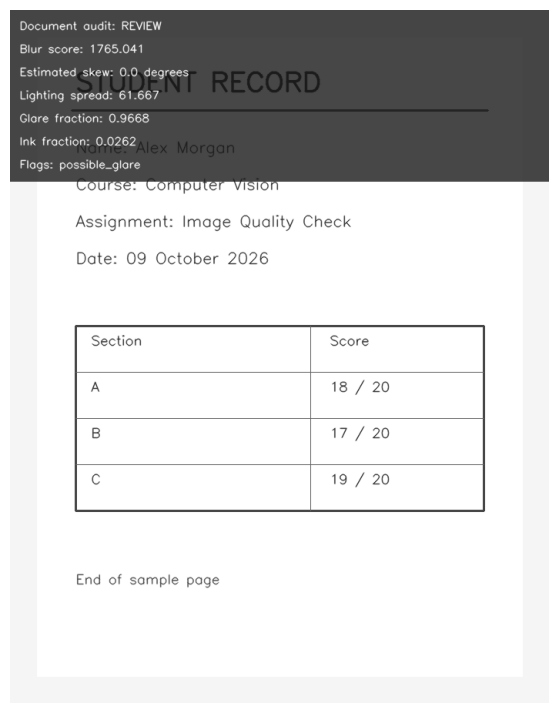

In [4]:
def make_diagnostic_image(image, result):
    preview = image.copy()
    lines = [
        f"Document audit: {'REVIEW' if result['issues'] else 'PASS (heuristic)' }",
        f"Blur score: {result['blur_laplacian_variance']}",
        f"Estimated skew: {result['estimated_skew_degrees']} degrees",
        f"Lighting spread: {result['illumination_spread_p95_p5']}",
        f"Glare fraction: {result['glare_pixel_fraction']:.4f}",
        f"Ink fraction: {result['estimated_ink_fraction']:.4f}",
        "Flags: " + (", ".join(result["issues"]) if result["issues"] else "none"),
    ]
    panel_height = 30 * len(lines) + 12
    overlay = preview.copy()
    cv2.rectangle(overlay, (0, 0), (preview.shape[1], panel_height), (25, 25, 25), -1)
    preview = cv2.addWeighted(overlay, 0.8, preview, 0.2, 0)
    for i, line in enumerate(lines):
        cv2.putText(preview, line[:100], (12, 25 + i * 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.48, (255, 255, 255), 1, cv2.LINE_AA)
    return preview

diagnostic = make_diagnostic_image(image, result)
plt.figure(figsize=(7, 9))
plt.imshow(cv2.cvtColor(diagnostic, cv2.COLOR_BGR2RGB))
plt.axis("off");
plt.show()

## 4. Try your own image

If you have a scan or page photo, put its path below and run the cell. For example, use `"my_scan.jpg"` if the file is in the same folder as this notebook. The generated sample above remains available if you leave the path empty.

In [5]:
IMAGE_PATH = ""  # Example: "my_scan.jpg"

if IMAGE_PATH.strip():
    custom_image = cv2.imread(IMAGE_PATH)
    if custom_image is None:
        raise FileNotFoundError(f"Could not open image: {IMAGE_PATH}")
else:
    custom_image = image

custom_result = analyze_image(custom_image)
print(json.dumps(custom_result, indent=2))

{
  "image_width": 700,
  "image_height": 900,
  "blur_laplacian_variance": 1765.041,
  "estimated_skew_degrees": 0.0,
  "illumination_spread_p95_p5": 61.667,
  "glare_pixel_fraction": 0.966773,
  "estimated_ink_fraction": 0.026157,
  "candidate_components": 149,
  "checks": {
    "possible_blur": false,
    "possible_skew": false,
    "uneven_illumination": false,
    "possible_glare": true,
    "low_ink_or_text_coverage": false
  },
  "issues": [
    "possible_glare"
  ]
}


## Notes

- A low Laplacian variance can suggest blur, but the score depends on the image and its resolution.
- Skew detection works best when the page has clear horizontal lines.
- Bright paper can be counted as glare, and tables or graphics can affect the ink estimate.
- Review the original image before making a decision. The output is a screening aid, not a certified quality score.

For a proper evaluation, test the thresholds on a labelled set of document images and report the false positives and false negatives.